# HW4 Problem 2: Circuit-board vibration

This experiment investigates how router bit size and cutting speed affect
vibration when cutting locating notches in printed circuit boards. Two bit
sizes, 1/16 and 1/8 inch, and two speeds, 40 and 90 rpm, are tested, with four
replications at each combination. Vibration is measured as the resultant
of three accelerometers.

The goal is to estimate the main and interaction effects, analyze the data
using ANOVA, and recommend settings that minimize mean vibration. Lower
vibration is desirable because vibration contributes to dimensional
variation in the notches.

This is a $2^2$ full factorial experiment with 16 observations.

| Factor | Low (-1) | High (+1) |
| --- | --- | --- |
| A: bit size | 1/16 in. | 1/8 in. |
| B: cutting speed | 40 rpm | 90 rpm |

I use $\alpha=0.05$ and the effects and plotting functions from Problem 1.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import f, t, probplot, levene

import doe

alpha = 0.05
plt.rcParams.update({"figure.figsize": (6.5, 4.2), "font.size": 11})

## Data and treatment means

The CSV rows are in standard order: $(1),a,b,ab$. Its header contains
replication labels. Each treatment has four measurements from separate
boards. Run this notebook from the folder containing `circuit-board.csv`
and `doe.py`.

In [2]:
data_path = Path("circuit-board.csv")
if not data_path.is_file():
    raise FileNotFoundError("Run this notebook from the HW4 folder.")

raw_data = pd.read_csv(data_path)
responses = raw_data.to_numpy(dtype=float)
if responses.shape != (4, 4) or not np.isfinite(responses).all():
    raise ValueError("Expected four treatments with four finite measurements each.")

n_replicates = responses.shape[1]
treatment_names = ["(1)", "a", "b", "ab"]
factor_a = np.array([-1, 1, -1, 1])
factor_b = np.array([-1, -1, 1, 1])
treatment_means = responses.mean(axis=1)

measurements = pd.DataFrame(
    responses, index=treatment_names, columns=raw_data.columns
)
measurements.index.name = "Treatment"
print("Vibration measurements:")
display(measurements)

summary = pd.DataFrame({
    "A": factor_a,
    "B": factor_b,
    "Bit size (in.)": ["1/16", "1/8", "1/16", "1/8"],
    "Speed (rpm)": [40, 40, 90, 90],
    "Replications": [n_replicates] * 4,
    "Mean vibration": treatment_means,
    "Sample variance": responses.var(axis=1, ddof=1),
}, index=treatment_names)
summary.index.name = "Treatment"
display(summary)

Vibration measurements:


,1,2,3,4
Treatment,,,,
(1),18.2,18.9,12.9,14.4
a,27.2,24.0,22.4,22.5
b,15.9,14.5,15.1,14.2
ab,41.0,43.9,36.3,39.9


,A,B,Bit size (in.),Speed (rpm),Replications,Mean vibration,Sample variance
Treatment,,,,,,,
(1),-1,-1,1/16,40,4,16.100,8.460000
a,1,-1,1/8,40,4,24.025,5.015833
b,-1,1,1/16,90,4,14.925,0.562500
ab,1,1,1/8,90,4,40.275,9.869167


## Main and interaction effects

A main effect compares the average response at the high and low levels,
averaging over the other factor. The AB effect is half the difference
between the effect of A at high B and its effect at low B. The calculations
use `doe.effects`.

In [3]:
effect_values = doe.effects(responses, n_replicates)
effect_table = pd.DataFrame(
    {"Effect": effect_values}, index=["A", "B", "AB"]
)
effect_table.index.name = "Term"
display(effect_table)

simple_effects = pd.Series({
    "A effect at 40 rpm": treatment_means[1] - treatment_means[0],
    "A effect at 90 rpm": treatment_means[3] - treatment_means[2],
    "B effect with 1/16-inch bit": treatment_means[2] - treatment_means[0],
    "B effect with 1/8-inch bit": treatment_means[3] - treatment_means[1],
}, name="Change in mean vibration")
display(simple_effects.to_frame())

,Effect
Term,
A,16.6375
B,7.5375
AB,8.7125


,Change in mean vibration
A effect at 40 rpm,7.925
A effect at 90 rpm,25.350
B effect with 1/16-inch bit,-1.175
B effect with 1/8-inch bit,16.250


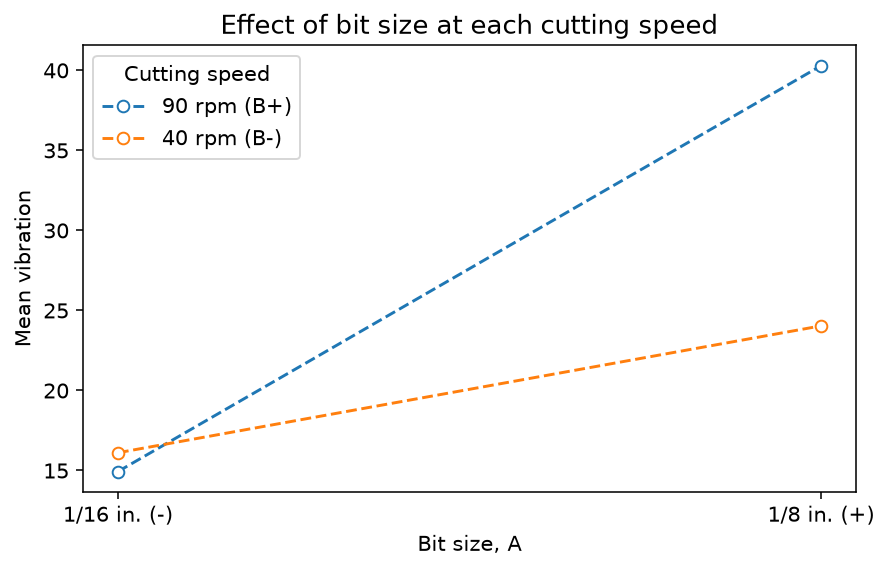

In [4]:
lines = doe.plot_effects(responses, n_replicates)
ax = lines[0].axes
ax.set_xticks([-1, 1], ["1/16 in. (-)", "1/8 in. (+)"])
ax.set_xlabel("Bit size, A")
ax.set_ylabel("Mean vibration")
ax.set_title("Effect of bit size at each cutting speed")
ax.legend(lines, ["90 rpm (B+)", "40 rpm (B-)"], title="Cutting speed")
lines[0].figure.tight_layout()
plt.show()

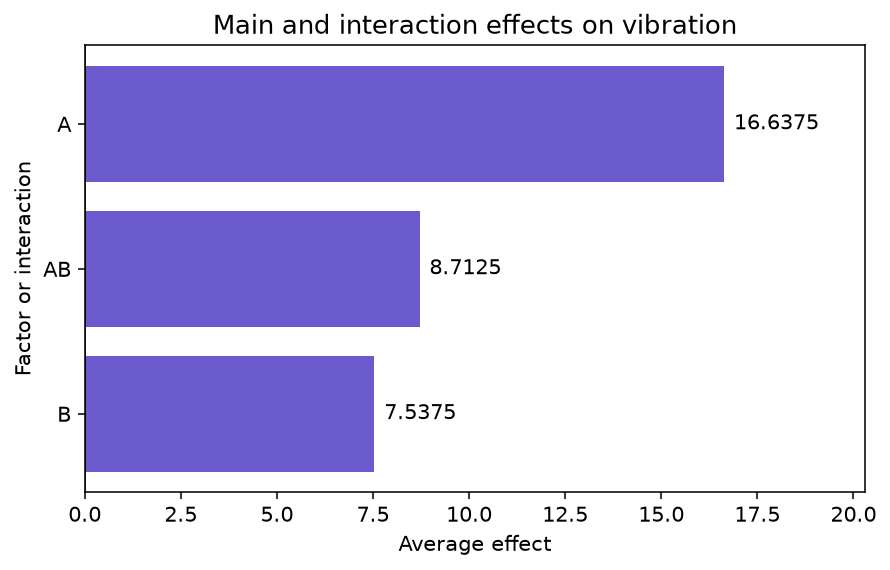

In [5]:
bars = doe.plot_tornado(responses, n_replicates)
ax = bars[0].axes
ax.set_title("Main and interaction effects on vibration")
for bar in bars:
    value = bar.get_width()
    ax.annotate(
        f"{value:.4f}",
        (value, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0), textcoords="offset points", va="center"
    )
ax.margins(x=0.22)
bars[0].figure.tight_layout()
plt.show()

The effects of A, B, and AB are **16.6375**, **7.5375**, and **8.7125**.
Bit size has the largest absolute effect. Increasing bit size raises mean
vibration by 7.925 at 40 rpm and by 25.350 at 90 rpm.

Increasing speed changes mean vibration by -1.175 with the 1/16-inch bit
and by +16.250 with the 1/8-inch bit. The different slopes show interaction:
$(25.350-7.925)/2=8.7125$. Speed should therefore be interpreted separately
at each bit size.

## Coded regression model

For predictors coded $-1$ and $+1$, each regression coefficient equals half its factorial effect. Including AB gives

$$\widehat y=\widehat\beta_0+\widehat\beta_Ax_A+
\widehat\beta_Bx_B+\widehat\beta_{AB}x_Ax_B.$$

The intercept is the grand mean. This model describes the four tested
combinations, the experiment does not estimate separate quadratic terms.

In [6]:
grand_mean = responses.mean()
beta_a = effect_values[0] / 2
beta_b = effect_values[1] / 2
beta_ab = effect_values[2] / 2

predicted_means = (
    grand_mean + beta_a * factor_a + beta_b * factor_b
    + beta_ab * factor_a * factor_b
)
fitted = np.repeat(predicted_means, n_replicates)
observed = responses.ravel()
residuals = observed - fitted

coefficient_table = pd.DataFrame({
    "Coefficient": [grand_mean, beta_a, beta_b, beta_ab]
}, index=["Intercept", "A", "B", "AB"])
display(coefficient_table)

,Coefficient
Intercept,23.83125
A,8.31875
B,3.76875
AB,4.35625


The fitted model is

$$\widehat y=23.83125+8.31875x_A+3.76875x_B+4.35625x_Ax_B.$$

It reproduces the four treatment means because there are four coefficients
and four distinct combinations.

## Analysis of variance

I test $H_0:A=0$, $H_0:B=0$, and $H_0:AB=0$ against nonzero effects at
$\alpha=0.05$. In this balanced design, each term has one degree of freedom
and $SS=n(\mathrm{effect})^2$.

The error sum of squares is the sum of squared deviations from the four
treatment means. It has $16-4=12$ degrees of freedom. For each term,
$F=MS_{\mathrm{term}}/MS_E$. SciPy supplies the F-distribution probabilities.
This follows the sums-of-squares method.

In [7]:
ss_terms = n_replicates * effect_values**2
ss_error = np.sum((responses - treatment_means[:, None])**2)
ss_total = np.sum((observed - grand_mean)**2)
df_error = responses.size - 4
ms_error = ss_error / df_error
f_values = ss_terms / ms_error
p_values = f.sf(f_values, 1, df_error)

anova = pd.DataFrame({
    "SS": [ss_terms[0], ss_terms[1], ss_terms[2], ss_error, ss_total],
    "df": [1, 1, 1, df_error, responses.size - 1],
    "MS": [ss_terms[0], ss_terms[1], ss_terms[2], ms_error, np.nan],
    "F": [f_values[0], f_values[1], f_values[2], np.nan, np.nan],
    "p-value": [p_values[0], p_values[1], p_values[2], np.nan, np.nan],
}, index=["A", "B", "AB", "Error", "Total"])
anova.index.name = "Source"
display(anova)

# Check that the separate contributions add to the total variation.
np.testing.assert_allclose(ss_terms.sum() + ss_error, ss_total)

model_f = (ss_terms.sum() / 3) / ms_error
model_p = f.sf(model_f, 3, df_error)
r_squared = 1 - ss_error / ss_total
print(f"Overall model: F(3, {df_error}) = {model_f:.4f}, p = {model_p:.6g}")
print(f"R squared = {r_squared:.6f}")
for term, p_value in zip(["A", "B", "AB"], p_values):
    decision = "Reject H0" if p_value < alpha else "Fail to reject H0"
    print(f"{term}: p = {p_value:.6g}; {decision} at alpha = {alpha}.")

,SS,df,MS,F,p-value
Source,,,,,
A,1107.225625,1,1107.225625,185.251595,1.174669e-08
B,227.255625,1,227.255625,38.022482,4.826292e-05
AB,303.630625,1,303.630625,50.800899,1.201078e-05
Error,71.722500,12,5.976875,NaN,NaN
Total,1709.834375,15,NaN,NaN,NaN


Overall model: F(3, 12) = 91.3583, p = 1.56859e-08
R squared = 0.958053
A: p = 1.17467e-08; Reject H0 at alpha = 0.05.
B: p = 4.82629e-05; Reject H0 at alpha = 0.05.
AB: p = 1.20108e-05; Reject H0 at alpha = 0.05.


The p-values for A, B, and AB are $1.17\times10^{-8}$, $4.83\times10^{-5}$,
and $1.20\times10^{-5}$. All are below 0.05, so I reject the three null
hypotheses under the ANOVA assumptions. I retain A, B, and AB in the model
and interpret speed at each bit size because the interaction is significant.

The error mean square is 5.976875. The model explains about 95.8% of the
observed variation; this measures fit to these data, not prediction accuracy
at untested settings.

## Residual checks

Classical ANOVA assumes independent errors with mean zero, approximately
normal distributions, and a common variance. I examine residuals versus
fitted values and a normal Q-Q plot. A median-centered Levene test provides
an additional check of equal variances across the four treatments.

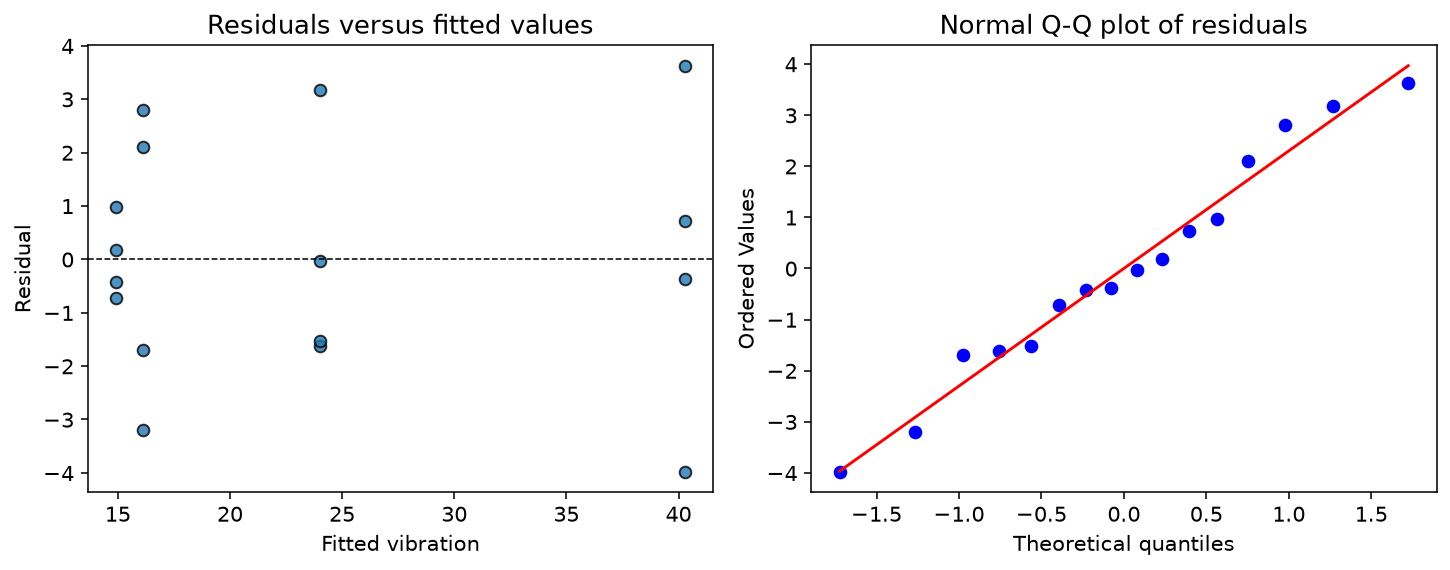

Median-centered Levene test: W = 1.6315, p = 0.2342


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].scatter(fitted, residuals, edgecolor="black", alpha=0.8)
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("Fitted vibration")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals versus fitted values")

probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of residuals")
fig.tight_layout()
plt.show()

variance_statistic, variance_p = levene(*responses, center="median")
print(f"Median-centered Levene test: W = {variance_statistic:.4f}, p = {variance_p:.4f}")

The Q-Q plot is approximately linear. Sample variances range from 0.5625
to 9.8692, but the median-centered Levene test does not reject equal
variances ($p=0.2342$). With only four replications per treatment, this does
not prove that the variances are equal. I retain the standard ANOVA while
recognizing the small sample and the unverified independence assumption.

## Comparison of speeds with the smaller bit

The smaller bit has lower mean vibration at both speeds. I compare its two
speeds using the difference 90 rpm minus 40 rpm. The standard error is
$\sqrt{MS_E(1/n+1/n)}$, using the pooled ANOVA error variance and 12 error
degrees of freedom. This is an unadjusted exploratory comparison.

In [9]:
speed_difference = treatment_means[2] - treatment_means[0]
difference_se = np.sqrt(ms_error * (1 / n_replicates + 1 / n_replicates))
difference_t = speed_difference / difference_se
difference_p = 2 * t.sf(abs(difference_t), df_error)
t_critical = t.ppf(1 - alpha / 2, df_error)
ci_lower = speed_difference - t_critical * difference_se
ci_upper = speed_difference + t_critical * difference_se

speed_comparison = pd.Series({
    "Mean difference (90 minus 40 rpm)": speed_difference,
    "Standard error": difference_se,
    "t statistic": difference_t,
    "p-value": difference_p,
    "95% CI lower limit": ci_lower,
    "95% CI upper limit": ci_upper,
}, name="Value")
display(speed_comparison.to_frame())

,Value
Mean difference (90 minus 40 rpm),-1.175000
Standard error,1.728710
t statistic,-0.679698
p-value,0.509595
95% CI lower limit,-4.941535
95% CI upper limit,2.591535


The difference is -1.175, with $p=0.510$ and a 95% confidence interval of
$[-4.942,\ 2.592]$. The data do not establish that increasing speed improves
vibration with the smaller bit, or that the two speeds are equivalent.
This is consistent with the significant AB interaction.

## Constrained minimization

For the four tested combinations, minimize $\widehat y$ subject to
$x_A,x_B\in\{-1,+1\}$. Checking all four combinations solves this
discrete problem exactly.

If the fitted bilinear model is assumed valid between the tested
levels, the continuous problem is

$$\min_{-1\le x_A\le1,\;-1\le x_B\le1}
\widehat y=23.83125+8.31875x_A+3.76875x_B+4.35625x_Ax_B.$$

Here $x_A=(A-3/32)/(1/32)$ for bit size A in inches and
$x_B=(B-65)/25$ for speed B in rpm. These bounds correspond to
$1/16\le A\le1/8$ inch and $40\le B\le90$ rpm.

Throughout this box,
$\partial\widehat y/\partial x_A=8.31875+4.35625x_B\ge3.9625>0$.
Therefore the minimum uses $x_A=-1$. Substitution gives
$\widehat y=15.5125-0.5875x_B$, which is minimized at $x_B=+1$.
The global minimum of the fitted model is therefore **14.925** at
**1/16 inch and 90 rpm**. This is also the lowest observed treatment
mean. Curvature between tested levels is not established by this design.

In [10]:
optimization_table = summary[
    ["Bit size (in.)", "Speed (rpm)", "Mean vibration"]
].copy()
optimization_table["Fitted vibration"] = predicted_means
display(optimization_table)

# Check the derivative signs used to establish the global model minimum.
minimum_slope_a = beta_a - abs(beta_ab)
slope_b_at_low_a = beta_b - beta_ab
assert minimum_slope_a > 0 and slope_b_at_low_a < 0

best_treatment = optimization_table["Fitted vibration"].idxmin()
recommended_setting = optimization_table.loc[[best_treatment]]
print("Settings that minimize the fitted response:")
display(recommended_setting)

,Bit size (in.),Speed (rpm),Mean vibration,Fitted vibration
Treatment,,,,
(1),1/16,40,16.100,16.100
a,1/8,40,24.025,24.025
b,1/16,90,14.925,14.925
ab,1/8,90,40.275,40.275


Settings that minimize the fitted response:


,Bit size (in.),Speed (rpm),Mean vibration,Fitted vibration
Treatment,,,,
b,1/16,90,14.925,14.925


## Recommended routine operating settings

I recommend a **1/16-inch bit at 90 rpm** to minimize vibration. This
combination has the lowest observed mean, **14.925**, and is the global
minimum of the fitted bilinear model within the stated bounds. The other
means are 16.100 for 1/16 inch at 40 rpm, 24.025 for 1/8 inch at 40 rpm,
and 40.275 for 1/8 inch at 90 rpm.

The smaller bit gives lower vibration at both speeds. The choice of 90 rpm
is based on its observed mean. The recommendation is limited to
the tested settings and the fitted model, rather than an unrestricted
physical optimum.